# Retail Sales Forecasting using Python & Machine Learning

**Beginner portfolio project** using simulated daily retail sales. Run the cells from top to bottom. The project generates its data and saves charts and result files into the `outputs/` folder.

> This dataset is synthetic and is for learning purposes.

## 1. Imports and setup

In [51]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings('ignore')
np.random.seed(42)
PROJECT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
OUT_DIR = os.path.join(PROJECT_DIR, 'outputs')
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

In [53]:
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['figure.dpi'] = 100

## 2. Generate a simulated daily dataset

We simulate a modest growth trend, weekly weekend effect, annual seasonality and random noise.

In [54]:
dates = pd.date_range('2023-01-01', '2025-12-31', freq='D')
data = pd.DataFrame({'Date': dates})
trend = np.linspace(1000, 1500, len(data))
weekly_effect = np.where(data['Date'].dt.dayofweek >= 5, 300, -100)
annual_effect = 200 * np.sin(2 * np.pi * data['Date'].dt.dayofyear / 365.25)
noise = np.random.normal(0, 120, len(data))
data['Sales'] = (trend + weekly_effect + annual_effect + noise).round(2)
data.to_csv(os.path.join(DATA_DIR, 'synthetic_retail_sales.csv'), index=False)
data.head()

,Date,Sales
0,2023-01-01,1363.05
1,2023-01-02,890.74
2,2023-01-03,988.95
3,2023-01-04,1097.88
4,2023-01-05,890.91


## 3. Create raw data issues (missing values and duplicate rows)

In [55]:
raw_data = data.copy()
missing_indices = np.random.choice(raw_data.index, size=30, replace=False)
raw_data.loc[missing_indices, 'Sales'] = np.nan
raw_data = pd.concat([raw_data, raw_data.sample(20, random_state=42)], ignore_index=True)
raw_data.to_csv(os.path.join(DATA_DIR, 'raw_retail_sales_with_issues.csv'), index=False)
raw_data.head()

,Date,Sales
0,2023-01-01,1363.05
1,2023-01-02,890.74
2,2023-01-03,988.95
3,2023-01-04,1097.88
4,2023-01-05,890.91


## 4. Explore the raw data

In [56]:
print('Shape:', raw_data.shape)
raw_data.info()
print('\nMissing values:\n', raw_data.isnull().sum())
print('\nDuplicate rows:', raw_data.duplicated().sum())
raw_data.describe()

Shape: (1116, 2)
<class 'pandas.DataFrame'>
RangeIndex: 1116 entries, 0 to 1115
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    1116 non-null   datetime64[us]
 1   Sales   1084 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 17.6 KB

Missing values:
 Date      0
Sales    32
dtype: int64

Duplicate rows: 20


,Date,Sales
count,1116,1084.000000
mean,2024-06-30 13:26:27.096774,1268.677915
min,2023-01-01 00:00:00,434.210000
25%,2023-09-30 18:00:00,1061.432500
50%,2024-07-01 12:00:00,1242.110000
75%,2025-03-30 06:00:00,1456.392500
max,2025-12-31 00:00:00,2162.180000
std,NaN,282.738780


## 5. Clean data

Remove exact duplicate rows, sort dates, and linearly interpolate missing sales for this simulated daily series.

In [57]:
data_cleaned = raw_data.drop_duplicates().sort_values('Date').copy()
data_cleaned['Sales'] = data_cleaned['Sales'].interpolate(method='linear')
data_cleaned = data_cleaned.reset_index(drop=True)
print('Shape:', data_cleaned.shape)
print('Missing values:', data_cleaned.isnull().sum().sum())
print('Duplicates:', data_cleaned.duplicated().sum())
data_cleaned.to_csv(os.path.join(OUT_DIR, 'cleaned_retail_sales.csv'), index=False)
data_cleaned.head()

Shape: (1096, 2)
Missing values: 0
Duplicates: 0


,Date,Sales
0,2023-01-01,1363.05
1,2023-01-02,890.74
2,2023-01-03,988.95
3,2023-01-04,1097.88
4,2023-01-05,890.91


## 6. EDA: daily sales trend

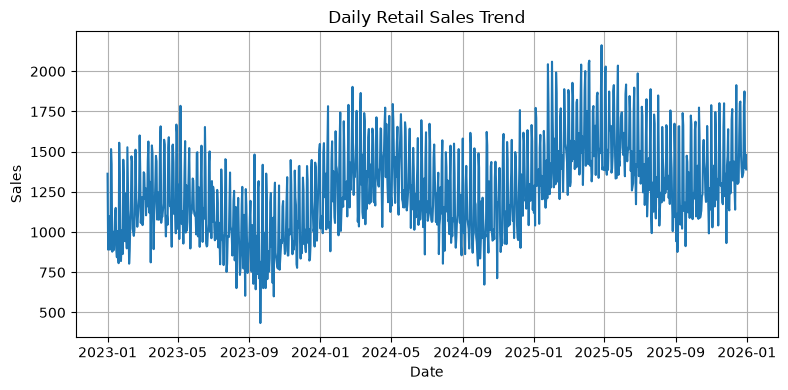

In [74]:
plt.figure()
plt.plot(data_cleaned['Date'], data_cleaned['Sales'])
plt.title('Daily Retail Sales Trend'); plt.xlabel('Date'); plt.ylabel('Sales'); plt.grid(True); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'sales_trend.png'), dpi=100)
plt.show()

### Basic sales metrics

In [59]:
print('Total sales:', round(data_cleaned['Sales'].sum(),2))
print('Average daily sales:', round(data_cleaned['Sales'].mean(),2))
print('Highest daily sales:', round(data_cleaned['Sales'].max(),2))
print('Lowest daily sales:', round(data_cleaned['Sales'].min(),2))
data_cleaned['Sales'].describe()

Total sales: 1389970.91
Average daily sales: 1268.22
Highest daily sales: 2162.18
Lowest daily sales: 434.21


count    1096.000000
mean     1268.221633
std       282.203969
min       434.210000
25%      1061.432500
50%      1242.635000
75%      1453.612500
max      2162.180000
Name: Sales, dtype: float64

### Average sales by weekday

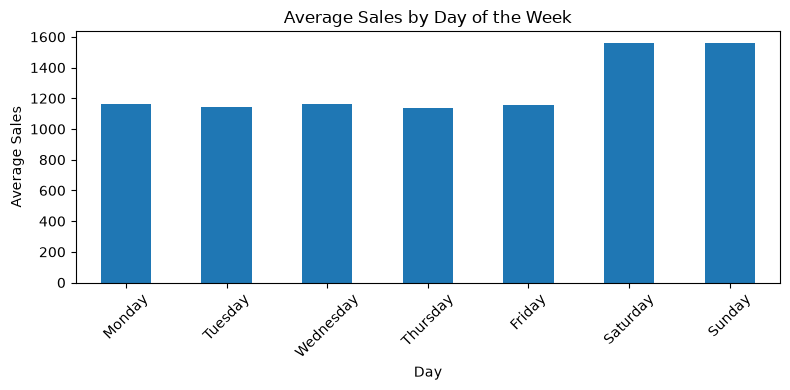

Day_Name
Monday       1161.742357
Tuesday      1140.237166
Wednesday    1161.883280
Thursday     1138.800449
Friday       1159.527724
Saturday     1557.546667
Sunday       1558.139968
Name: Sales, dtype: float64

In [60]:
data_cleaned['Day_Name'] = data_cleaned['Date'].dt.day_name()
weekday_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
weekday_sales = data_cleaned.groupby('Day_Name')['Sales'].mean().reindex(weekday_order)
weekday_sales.plot(kind='bar', title='Average Sales by Day of the Week')
plt.xlabel('Day'); plt.ylabel('Average Sales'); plt.xticks(rotation=45); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'weekday_sales.png'), dpi=200); plt.show()
weekday_sales

### Average sales by month

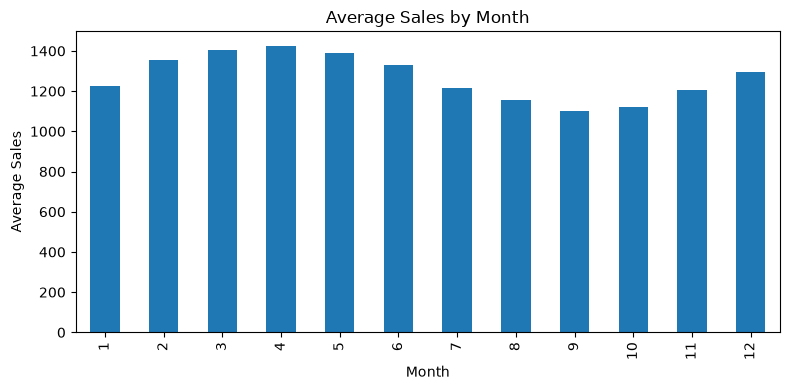

Month
1     1227.035753
2     1352.601647
3     1405.927258
4     1426.143667
5     1388.570538
6     1330.934000
7     1216.384409
8     1155.163763
9     1101.847111
10    1123.079032
11    1204.829333
12    1293.106989
Name: Sales, dtype: float64

In [61]:
data_cleaned['Month'] = data_cleaned['Date'].dt.month
monthly_sales = data_cleaned.groupby('Month')['Sales'].mean()
monthly_sales.plot(kind='bar', title='Average Sales by Month')
plt.xlabel('Month'); plt.ylabel('Average Sales'); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'monthly_sales.png'), dpi=100); plt.show()
monthly_sales

### Total sales by year

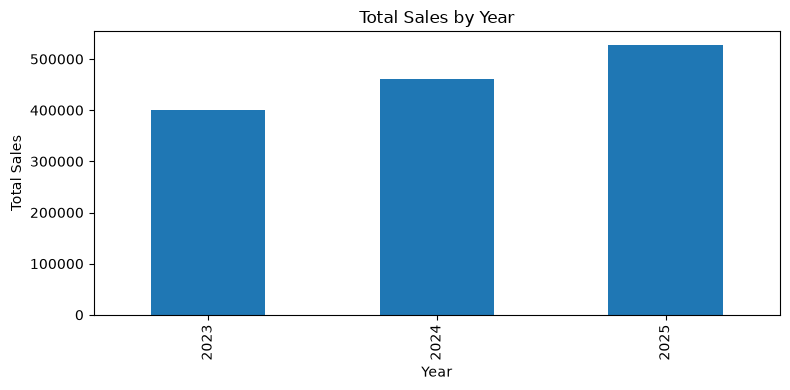

Year
2023    400721.010
2024    461507.585
2025    527742.315
Name: Sales, dtype: float64

In [62]:
data_cleaned['Year'] = data_cleaned['Date'].dt.year
yearly_sales = data_cleaned.groupby('Year')['Sales'].sum()
yearly_sales.plot(kind='bar', title='Total Sales by Year')
plt.xlabel('Year'); plt.ylabel('Total Sales'); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'yearly_sales.png'), dpi=100); plt.show()
yearly_sales

## 7. Feature engineering

Calendar features and lag/rolling features. Rolling means are shifted first to avoid using the target day's sales in its own features.

In [63]:
data_ml = data_cleaned.copy()
data_ml['Day'] = data_ml['Date'].dt.day
data_ml['Month'] = data_ml['Date'].dt.month
data_ml['Year'] = data_ml['Date'].dt.year
data_ml['DayOfWeek'] = data_ml['Date'].dt.dayofweek
data_ml['IsWeekend'] = (data_ml['DayOfWeek'] >= 5).astype(int)
data_ml['Sales_Lag_1'] = data_ml['Sales'].shift(1)
data_ml['Sales_Lag_7'] = data_ml['Sales'].shift(7)
data_ml['Sales_Lag_14'] = data_ml['Sales'].shift(14)
data_ml['Sales_Lag_28'] = data_ml['Sales'].shift(28)
data_ml['Rolling_Mean_7'] = data_ml['Sales'].shift(1).rolling(7).mean()
data_ml['Rolling_Mean_28'] = data_ml['Sales'].shift(1).rolling(28).mean()
data_ml = data_ml.dropna().reset_index(drop=True)
features = ['Day','Month','Year','DayOfWeek','IsWeekend','Sales_Lag_1','Sales_Lag_7','Sales_Lag_14','Sales_Lag_28','Rolling_Mean_7','Rolling_Mean_28']
target = 'Sales'
data_ml.head()

,Date,Sales,Day_Name,Month,Year,Day,DayOfWeek,IsWeekend,Sales_Lag_1,Sales_Lag_7,Sales_Lag_14,Sales_Lag_28,Rolling_Mean_7,Rolling_Mean_28
0,2023-01-29,1336.40,Sunday,1,2023,29,6,1,1450.06,1356.39,1150.44,1363.05,1060.721429,1048.980000
1,2023-01-30,976.93,Monday,1,2023,30,0,0,1336.40,995.23,893.73,890.74,1057.865714,1048.028214
2,2023-01-31,943.17,Tuesday,1,2023,31,1,0,976.93,819.78,843.42,988.95,1055.251429,1051.106429
3,2023-02-01,1241.05,Wednesday,2,2023,1,2,0,943.17,929.02,1006.42,1097.88,1072.878571,1049.471429
4,2023-02-02,1020.53,Thursday,2,2023,2,3,0,1241.05,1011.23,863.47,890.91,1117.454286,1054.584643


## 8. Chronological train/test split

Hold out the final 30 days for a rolling forecast evaluation. No random shuffling.

In [64]:
forecast_horizon = 30
cutoff_date = data_cleaned['Date'].max() - pd.Timedelta(days=forecast_horizon-1)
train_ml = data_ml[data_ml['Date'] < cutoff_date].copy()
test_ml = data_ml[data_ml['Date'] >= cutoff_date].copy()
X_train, y_train = train_ml[features], train_ml[target]
X_test, y_test = test_ml[features], test_ml[target]
test_dates = test_ml['Date'].tolist()
history_before_test = data_cleaned.loc[data_cleaned['Date'] < cutoff_date, 'Sales'].tolist()
print('Train rows:', len(X_train), 'Test rows:', len(X_test), 'Test starts:', cutoff_date)

Train rows: 1038 Test rows: 30 Test starts: 2025-12-02 00:00:00


## 9. Train models

In [65]:
linear_model = LinearRegression().fit(X_train, y_train)
rf_model = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(X_train, y_train)
print('Models trained.')

Models trained.


## 10. Recursive forecasting functions

For multi-day forecasts, each predicted value is added to the history used to build the next day's features.

In [66]:
def make_features_for_date(date, history):
    dow = date.dayofweek
    row = {'Day': date.day, 'Month': date.month, 'Year': date.year, 'DayOfWeek': dow, 'IsWeekend': int(dow >= 5),
           'Sales_Lag_1': history[-1], 'Sales_Lag_7': history[-7], 'Sales_Lag_14': history[-14], 'Sales_Lag_28': history[-28],
           'Rolling_Mean_7': np.mean(history[-7:]), 'Rolling_Mean_28': np.mean(history[-28:])}
    return pd.DataFrame([row])[features]

def recursive_forecast(model, dates_to_predict, history):
    history = list(history)
    predictions = []
    for date in dates_to_predict:
        x_next = make_features_for_date(date, history)
        pred = float(model.predict(x_next)[0])
        predictions.append(pred)
        history.append(pred)
    return np.array(predictions)

## 11. Evaluate on the held-out 30 days

In [67]:
linear_predictions = recursive_forecast(linear_model, test_dates, history_before_test)
rf_predictions = recursive_forecast(rf_model, test_dates, history_before_test)

def evaluate_model(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted), 'RMSE': np.sqrt(mean_squared_error(actual, predicted)), 'R2': r2_score(actual, predicted)}

model_comparison = pd.DataFrame([evaluate_model(y_test, linear_predictions), evaluate_model(y_test, rf_predictions)], index=['Linear Regression','Random Forest'])
model_comparison.to_csv(os.path.join(OUT_DIR, 'model_comparison.csv'))
model_comparison

,MAE,RMSE,R2
Linear Regression,164.766396,183.283837,0.253851
Random Forest,151.580588,171.414675,0.347361


### Test predictions table

In [68]:
results = pd.DataFrame({'Date': test_dates, 'Actual_Sales': y_test.values, 'Linear_Regression_Predictions': linear_predictions, 'Random_Forest_Predictions': rf_predictions})
results.to_csv(os.path.join(OUT_DIR, 'test_predictions.csv'), index=False)
results.head()

,Date,Actual_Sales,Linear_Regression_Predictions,Random_Forest_Predictions
0,2025-12-02,1134.96,1219.064891,1163.150084
1,2025-12-03,1433.10,1220.088255,1259.392538
2,2025-12-04,1241.19,1211.214823,1159.034684
3,2025-12-05,1342.43,1221.661530,1193.814448
4,2025-12-06,1698.79,1614.499755,1596.454439


### Actual vs Linear Regression

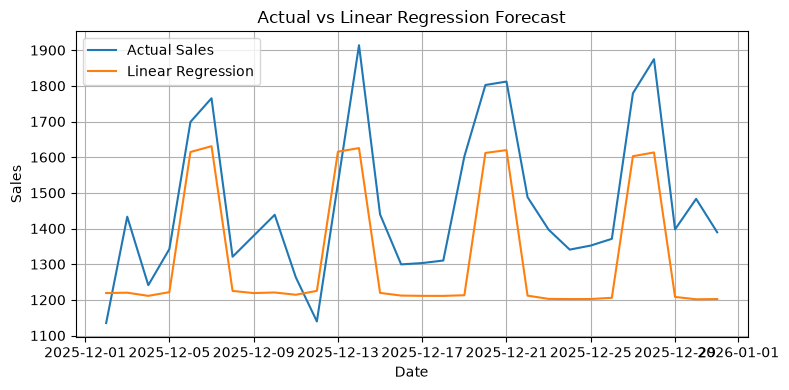

In [69]:
plt.figure()
plt.plot(results['Date'], results['Actual_Sales'], label='Actual Sales')
plt.plot(results['Date'], results['Linear_Regression_Predictions'], label='Linear Regression')
plt.title('Actual vs Linear Regression Forecast'); plt.xlabel('Date'); plt.ylabel('Sales'); plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'linear_test_forecast.png')); plt.show()

### Actual vs Random Forest

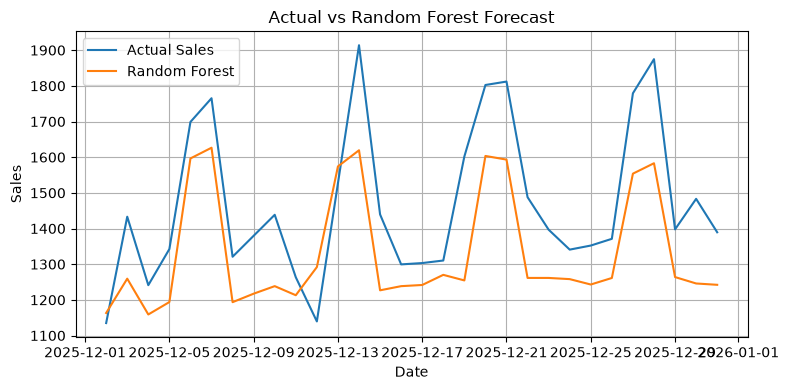

In [70]:
plt.figure()
plt.plot(results['Date'], results['Actual_Sales'], label='Actual Sales')
plt.plot(results['Date'], results['Random_Forest_Predictions'], label='Random Forest')
plt.title('Actual vs Random Forest Forecast'); plt.xlabel('Date'); plt.ylabel('Sales'); plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'random_forest_test_forecast.png')); plt.show()

## 12. Choose a model and forecast the next 30 days

We choose the model with the lower MAE from the test period, then retrain it on all historical data.

In [71]:
selected_model_name = 'Random Forest' if model_comparison.loc['Random Forest','MAE'] < model_comparison.loc['Linear Regression','MAE'] else 'Linear Regression'
print('Selected by test MAE:', selected_model_name)
final_linear = LinearRegression().fit(data_ml[features], data_ml[target])
final_rf = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=2, random_state=42, n_jobs=-1).fit(data_ml[features], data_ml[target])
future_dates = pd.date_range(data_cleaned['Date'].max()+pd.Timedelta(days=1), periods=30, freq='D')
full_history = data_cleaned['Sales'].tolist()
future_linear = recursive_forecast(final_linear, future_dates, full_history)
future_rf = recursive_forecast(final_rf, future_dates, full_history)
future_results = pd.DataFrame({'Date': future_dates, 'Linear_Regression_Forecast': future_linear, 'Random_Forest_Forecast': future_rf})
future_results['Forecasted_Sales'] = future_rf if selected_model_name == 'Random Forest' else future_linear
future_results.to_csv(os.path.join(OUT_DIR, 'retail_sales_forecast_30_days.csv'), index=False)
future_results.head()

Selected by test MAE: Random Forest


,Date,Linear_Regression_Forecast,Random_Forest_Forecast,Forecasted_Sales
0,2026-01-01,1410.885045,1384.075104,1384.075104
1,2026-01-02,1423.745061,1479.765233,1479.765233
2,2026-01-03,1822.574768,1822.583635,1822.583635
3,2026-01-04,1838.024525,1870.069479,1870.069479
4,2026-01-05,1435.462769,1426.743300,1426.743300


### Forecast chart

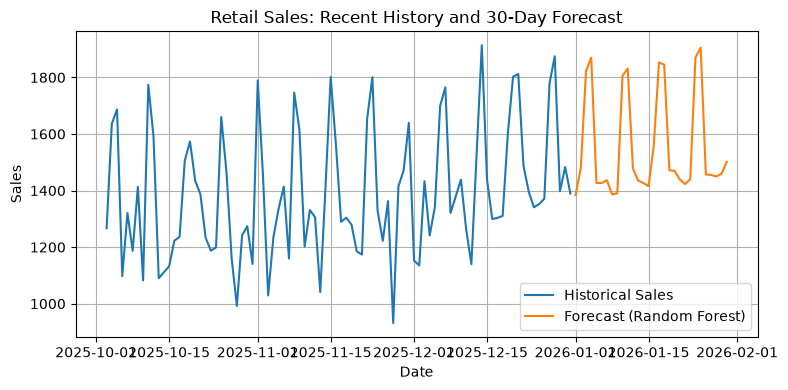

In [72]:
plt.figure()
plt.plot(data_cleaned['Date'].tail(90), data_cleaned['Sales'].tail(90), label='Historical Sales')
plt.plot(future_results['Date'], future_results['Forecasted_Sales'], label=f'Forecast ({selected_model_name})')
plt.title('Retail Sales: Recent History and 30-Day Forecast'); plt.xlabel('Date'); plt.ylabel('Sales'); plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'sales_forecast_30_days.png')); plt.show()

## 13. Business insights and summary

In [73]:
best_day = weekday_sales.idxmax(); lowest_day = weekday_sales.idxmin()
best_month = monthly_sales.idxmax(); lowest_month = monthly_sales.idxmin()
forecast_total = future_results['Forecasted_Sales'].sum(); forecast_average = future_results['Forecasted_Sales'].mean()
summary = f'''PROJECT SUMMARY\nBest average sales weekday: {best_day} ({weekday_sales[best_day]:.2f})\nLowest average sales weekday: {lowest_day} ({weekday_sales[lowest_day]:.2f})\nBest average sales month number: {best_month} ({monthly_sales[best_month]:.2f})\nLowest average sales month number: {lowest_month} ({monthly_sales[lowest_month]:.2f})\nSelected model based on rolling test MAE: {selected_model_name}\nForecast total sales next 30 days: {forecast_total:.2f}\nForecast average daily sales next 30 days: {forecast_average:.2f}\n'''
with open(os.path.join(OUT_DIR, 'business_summary.txt'), 'w', encoding='utf-8') as f: f.write(summary)
print(summary)

PROJECT SUMMARY
Best average sales weekday: Sunday (1558.14)
Lowest average sales weekday: Thursday (1138.80)
Best average sales month number: 4 (1426.14)
Lowest average sales month number: 9 (1101.85)
Selected model based on rolling test MAE: Random Forest
Forecast total sales next 30 days: 46614.14
Forecast average daily sales next 30 days: 1553.80



## 14. Files created

- `data/synthetic_retail_sales.csv`: generated clean synthetic data
- `data/raw_retail_sales_with_issues.csv`: raw data with missing values and duplicate records
- `outputs/cleaned_retail_sales.csv`: cleaned data
- `outputs/model_comparison.csv`: evaluation metrics
- `outputs/test_predictions.csv`: rolling test forecasts
- `outputs/retail_sales_forecast_30_days.csv`: future forecast
- `outputs/*.png`: charts
- `outputs/business_summary.txt`: summary

**Reminder:** Results are simulated and should be described as synthetic in a portfolio.

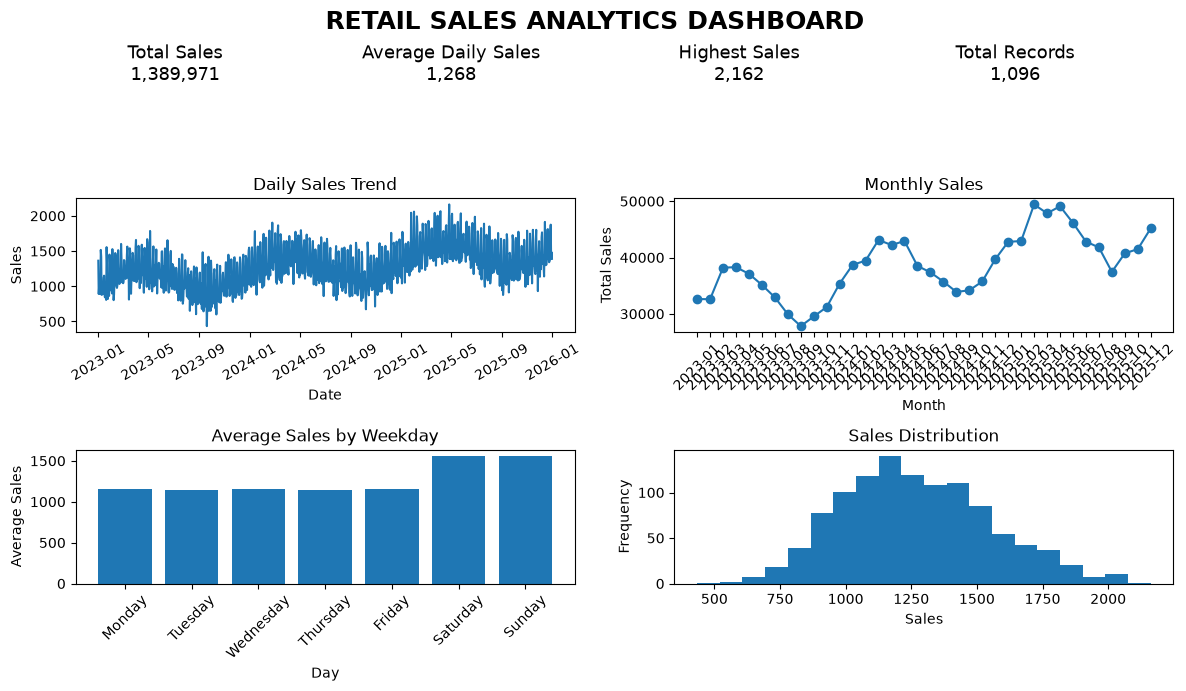

Dashboard saved at: C:\Users\prana\OneDrive\Documents\Project 2\Retail-Sales-Forecasting-Python\outputs\sales_dashboard.png


In [75]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# Ensure Date is in datetime format
data_cleaned['Date'] = pd.to_datetime(data_cleaned['Date'])

# Calculate KPIs
total_sales = data_cleaned['Sales'].sum()
average_daily_sales = data_cleaned['Sales'].mean()
highest_sales = data_cleaned['Sales'].max()
total_records = len(data_cleaned)

highest_sales_date = data_cleaned.loc[
    data_cleaned['Sales'].idxmax(), 'Date'
]

# Monthly Sales
monthly_sales = data_cleaned.groupby(
    data_cleaned['Date'].dt.to_period('M')
)['Sales'].sum()

# Weekday Sales
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_sales = data_cleaned.groupby(
    data_cleaned['Date'].dt.day_name()
)['Sales'].mean().reindex(weekday_order)

# Create Dashboard
fig = plt.figure(figsize=(12, 7))

fig.suptitle(
    'RETAIL SALES ANALYTICS DASHBOARD',
    fontsize=18,
    fontweight='bold'
)

# KPI Section
fig.text(0.15, 0.88, f'Total Sales\n{total_sales:,.0f}',
         ha='center', fontsize=13)

fig.text(0.38, 0.88, f'Average Daily Sales\n{average_daily_sales:,.0f}',
         ha='center', fontsize=13)

fig.text(0.62, 0.88, f'Highest Sales\n{highest_sales:,.0f}',
         ha='center', fontsize=13)

fig.text(0.85, 0.88, f'Total Records\n{total_records:,}',
         ha='center', fontsize=13)

# Chart 1: Sales Trend
ax1 = fig.add_subplot(2, 2, 1)

ax1.plot(data_cleaned['Date'], data_cleaned['Sales'])
ax1.set_title('Daily Sales Trend')
ax1.set_xlabel('Date')
ax1.set_ylabel('Sales')
ax1.tick_params(axis='x', rotation=30)

# Chart 2: Monthly Sales
ax2 = fig.add_subplot(2, 2, 2)

ax2.plot(monthly_sales.index.astype(str), monthly_sales.values,
         marker='o')

ax2.set_title('Monthly Sales')
ax2.set_xlabel('Month')
ax2.set_ylabel('Total Sales')
ax2.tick_params(axis='x', rotation=45)

# Chart 3: Weekday Sales
ax3 = fig.add_subplot(2, 2, 3)

ax3.bar(weekday_sales.index, weekday_sales.values)

ax3.set_title('Average Sales by Weekday')
ax3.set_xlabel('Day')
ax3.set_ylabel('Average Sales')
ax3.tick_params(axis='x', rotation=45)

# Chart 4: Sales Distribution
ax4 = fig.add_subplot(2, 2, 4)

ax4.hist(data_cleaned['Sales'], bins=20)

ax4.set_title('Sales Distribution')
ax4.set_xlabel('Sales')
ax4.set_ylabel('Frequency')

# Adjust layout
plt.tight_layout(rect=[0, 0, 1, 0.82])

# Save Dashboard
dashboard_path = os.path.join(OUT_DIR, 'sales_dashboard.png')

plt.savefig(dashboard_path, dpi=200, bbox_inches='tight')

plt.show()

print("Dashboard saved at:", dashboard_path)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import FancyBboxPatch
from pathlib import Path

# ==========================================
# 1. LOAD DATA
# ==========================================

cleaned_path = Path("outputs/cleaned_retail_sales.csv")
forecast_path = Path("outputs/retail_sales_forecast_30_days.csv")

df = pd.read_csv(cleaned_path)
forecast_df = pd.read_csv(forecast_path)

# Identify date and sales columns
date_col = next(c for c in df.columns if c.lower() in ["date", "order_date"])
sales_col = next(c for c in df.columns if c.lower() in ["sales", "sales_amount", "revenue"])

forecast_date_col = next(
    c for c in forecast_df.columns if c.lower() in ["date", "forecast_date"]
)

forecast_sales_col = next(
    c for c in forecast_df.columns
    if c.lower() in ["predicted_sales", "forecast_sales", "sales", "prediction"]
)

df[date_col] = pd.to_datetime(df[date_col])
forecast_df[forecast_date_col] = pd.to_datetime(forecast_df[forecast_date_col])

df = df.sort_values(date_col)
forecast_df = forecast_df.sort_values(forecast_date_col)

# ==========================================
# 2. CALCULATE KPI METRICS
# ==========================================

total_sales = df[sales_col].sum()
avg_sales = df[sales_col].mean()
max_sales = df[sales_col].max()
forecast_total = forecast_df[forecast_sales_col].sum()

# ==========================================
# 3. DARK DASHBOARD DESIGN
# ==========================================

bg = "#0B1120"
panel = "#151F32"
text_color = "#F1F5F9"
muted = "#94A3B8"
cyan = "#38BDF8"
green = "#34D399"
purple = "#A78BFA"
orange = "#FBBF24"

plt.rcParams["font.family"] = "DejaVu Sans"

fig = plt.figure(figsize=(18, 11), facecolor=bg)

gs = fig.add_gridspec(
    3, 4,
    height_ratios=[0.75, 2, 1.5],
    hspace=0.40,
    wspace=0.30
)

# ==========================================
# 4. DASHBOARD TITLE
# ==========================================

fig.text(
    0.05, 0.96,
    "RETAIL SALES ANALYTICS",
    fontsize=24,
    fontweight="bold",
    color=text_color
)

fig.text(
    0.05, 0.925,
    "Historical performance  |  Sales trends  |  30-day forecast",
    fontsize=12,
    color=muted
)

# ==========================================
# 5. KPI CARDS
# ==========================================

kpi_values = [
    ("TOTAL SALES", f"{total_sales:,.0f}", cyan),
    ("AVERAGE DAILY SALES", f"{avg_sales:,.0f}", green),
    ("HIGHEST DAILY SALES", f"{max_sales:,.0f}", orange),
    ("NEXT 30-DAY FORECAST", f"{forecast_total:,.0f}", purple)
]

kpi_positions = [
    (0, 0), (0, 1), (0, 2), (0, 3)
]

for i, (label, value, accent) in enumerate(kpi_values):

    ax = fig.add_subplot(gs[0, i])

    ax.set_facecolor(panel)
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.text(
        0.08, 0.72, label,
        transform=ax.transAxes,
        color=muted,
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        0.08, 0.30, value,
        transform=ax.transAxes,
        color=accent,
        fontsize=21,
        fontweight="bold"
    )

# ==========================================
# 6. SALES TREND + FORECAST CHART
# ==========================================

ax1 = fig.add_subplot(gs[1, :])

ax1.set_facecolor(panel)

# Historical sales
ax1.plot(
    df[date_col],
    df[sales_col],
    color=cyan,
    linewidth=1.8,
    label="Historical Sales"
)

# Forecast
ax1.plot(
    forecast_df[forecast_date_col],
    forecast_df[forecast_sales_col],
    color=orange,
    linewidth=2.5,
    linestyle="--",
    label="Forecast Sales"
)

# Highlight forecast area
ax1.axvspan(
    forecast_df[forecast_date_col].min(),
    forecast_df[forecast_date_col].max(),
    alpha=0.10,
    color=orange
)

ax1.set_title(
    "Sales Trend & 30-Day Forecast",
    color=text_color,
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=15
)

ax1.set_xlabel("Date", color=muted)
ax1.set_ylabel("Sales", color=muted)

ax1.tick_params(colors=muted)

ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax1.grid(alpha=0.15)

ax1.legend(
    facecolor=panel,
    edgecolor=panel,
    labelcolor=text_color
)

for spine in ax1.spines.values():
    spine.set_color("#25344D")

# ==========================================
# 7. WEEKDAY SALES ANALYSIS
# ==========================================

ax2 = fig.add_subplot(gs[2, 0:2])

df["Weekday"] = df[date_col].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    df.groupby("Weekday")[sales_col]
    .mean()
    .reindex(weekday_order)
)

bars = ax2.bar(
    weekday_sales.index,
    weekday_sales.values,
    color=green,
    alpha=0.90
)

ax2.set_title(
    "Average Sales by Weekday",
    color=text_color,
    fontsize=14,
    fontweight="bold",
    loc="left"
)

ax2.tick_params(axis="x", rotation=35, colors=muted)
ax2.tick_params(axis="y", colors=muted)
ax2.grid(axis="y", alpha=0.15)

for spine in ax2.spines.values():
    spine.set_color("#25344D")

# ==========================================
# 8. MONTHLY SALES ANALYSIS
# ==========================================

ax3 = fig.add_subplot(gs[2, 2:4])

df["Month"] = df[date_col].dt.month

monthly_sales = df.groupby("Month")[sales_col].mean()

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

ax3.bar(
    month_names,
    monthly_sales.reindex(range(1, 13)),
    color=purple,
    alpha=0.90
)

ax3.set_title(
    "Average Sales by Month",
    color=text_color,
    fontsize=14,
    fontweight="bold",
    loc="left"
)

ax3.tick_params(axis="x", colors=muted)
ax3.tick_params(axis="y", colors=muted)
ax3.grid(axis="y", alpha=0.15)

for spine in ax3.spines.values():
    spine.set_color("#25344D")

# ==========================================
# 9. FINAL LAYOUT
# ==========================================

fig.text(
    0.05, 0.02,
    "DATA ANALYTICS PROJECT  |  PYTHON • PANDAS • MATPLOTLIB",
    color=muted,
    fontsize=10
)

plt.subplots_adjust(
    top=0.89,
    bottom=0.09,
    left=0.05,
    right=0.97
)

plt.savefig(
    "outputs/sales_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=bg
)

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'outputs\\cleaned_retail_sales.csv'